# Explain

What the chosen model reads in a narrative: the words and phrases with the largest weights, overall and for the three biggest products, how steady those weights are, and a few narratives with their scores. Everything here is on the training set. The notebook takes about 6 minutes to run.

In [1]:
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
from src.data import load_text, time_split
from src.explain import narrative_terms, term_weights, top_terms
from src.models import chosen, cross_validate, split_folds

FIGURES = "../reports/figures/"

In [2]:
train, test = time_split(load_text())
X_train = train["text"]
y_train = train["disputed"]
opening = X_train.str.lower().str[:100]
overall = y_train.mean()

## The weights

`chosen()` is fitted on the whole training set. Its logistic regression has one weight for each word or phrase. A positive weight pushes the score towards a dispute and a negative one pushes it away. `narratives` is how many training narratives contain the term, and `dispute_rate` is how often those were disputed, against 23.2% overall.

In [3]:
model = chosen().fit(X_train, y_train)
weights = term_weights(model, X_train, y_train)
len(weights), weights.index.str.contains(" ").sum()

(284161, np.int64(266622))

In [4]:
top = top_terms(weights, 20)
top.round(3)

weight  narratives  dispute_rate
towards scottrade        3.024         151         0.801
        equifax          2.955        5315         0.344
        tcpa             2.185         135         0.696
        chase            1.761        3874         0.291
        attached         1.571        6901         0.326
        illegal          1.563        3547         0.323
        without          1.512       12856         0.287
        of               1.504       84780         0.248
        violated         1.483        1934         0.358
        cfpb             1.417        5081         0.351
        even             1.391       19820         0.268
        why              1.388       13528         0.269
        consumer         1.337        7657         0.318
        and              1.336      100485         0.237
        by               1.332       42403         0.270
        they             1.289       74682         0.241
        bb               1.288         278         0.338
        against          1.277        9338         0.311
        any              1.266       31113         0.272
        fcra             1.240        3234         0.333
away    ve              -1.542        6912         0.221
        payday          -1.490        1145         0.138
        rushcard        -1.403         298         0.050
        experian        -1.335        4317         0.190
        update          -1.215        2515         0.227
        my bank         -1.179        5351         0.208
        payday loan     -1.172         855         0.136
        error           -1.154        4862         0.243
        rush            -1.074         341         0.106
        phone           -1.053       21815         0.226
        items on        -1.029         508         0.199
        information on  -1.001        3724         0.258
        calling         -0.992        8410         0.202
        to them         -0.987        7668         0.246
        name is         -0.981        1884         0.197
        rush card       -0.978         197         0.030
        fee             -0.966        7834         0.215
        necessary       -0.959        1761         0.238
        late fee        -0.953        1864         0.178
        xxxx this       -0.952        4176         0.265

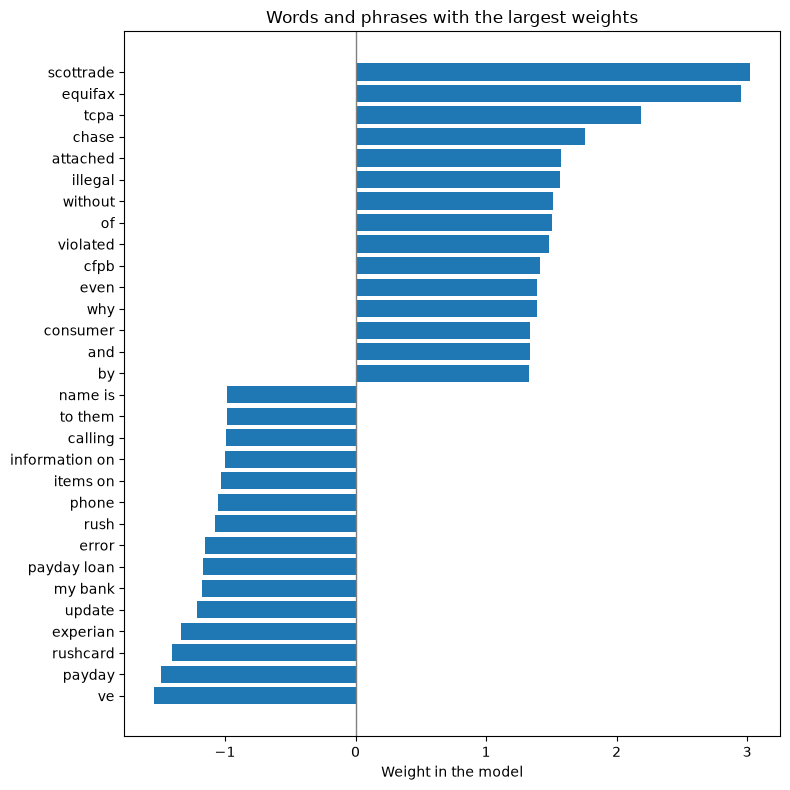

In [5]:
ordered = weights.sort_values("weight")
ends = pd.concat([ordered.head(15), ordered.tail(15)])

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(ends.index, ends["weight"])
ax.axvline(0, color="grey", linewidth=1)
ax.set_xlabel("Weight in the model")
ax.set_title("Words and phrases with the largest weights")
fig.tight_layout()
fig.savefig(FIGURES + "term_weights.png", dpi=150)
plt.show()

The model has 284,161 terms and 266,622 of them are two-word phrases, but the 20 largest weights towards a dispute are all single words. Legal wording is there, as in the EDA: illegal, violated, cfpb, fcra, and `tcpa` (the Telephone Consumer Protection Act), which is in only 135 narratives and 69.6% of those were disputed. `attached` comes from consumers who sent documents with the complaint ("see attached", "I have attached"). Four of the 20 are company names: scottrade, equifax, chase and `bb`, which is what the vectorizer keeps of BB&T.

Away from a dispute it's payday loans, fees, phone calls (`phone`, `calling`) and two more names, experian and RushCard. Nine of those 20 are phrases.

In [6]:
away = top.loc["away"]
away[away["dispute_rate"] > overall].round(3)

,weight,narratives,dispute_rate
error,-1.154,4862,0.243
information on,-1.001,3724,0.258
to them,-0.987,7668,0.246
necessary,-0.959,1761,0.238
xxxx this,-0.952,4176,0.265


Five of the 20 terms that push away from a dispute are in narratives that are disputed more often than the overall 23.2%, with `xxxx this` at 26.5%. The raw rate includes length. A long narrative has more of every term and long narratives are disputed more, which is why nearly every word in the EDA sat above the overall rate. The weight is what the term adds once the rest of the narrative is counted, so the two can point in different directions.

In [7]:
weights.loc[["of", "and", "by", "they", "my", "had", "xxxx", "xxdate", "xxmoney"]].round(3)

,weight,narratives,dispute_rate
of,1.504,84780,0.248
and,1.336,100485,0.237
by,1.332,42403,0.270
they,1.289,74682,0.241
my,-0.932,93687,0.234
had,-0.929,44636,0.241
xxxx,0.598,92451,0.241
xxdate,0.898,29921,0.261
xxmoney,0.465,34511,0.245


In [8]:
X_train.str.lower().str.extract(r"(\w+) 've\b", expand=False).value_counts().head(4)

text
i        5661
they      453
we        360
would     125
Name: count, dtype: int64

Stop words have some of the largest weights, which fits the gain from leaving them in. `of`, `and`, `by` and `they` push towards a dispute, and `my` and `had` push away. The most negative weight of all belongs to `ve`. CFPB's text puts a space before the apostrophe and the vectorizer drops one-letter words, so `ve` is what's left of "I 've", "they 've" and "we 've". These words are in most narratives, so their weights work through how much of the narrative they take up. My reading is that a narrative about what the company did (`they`, `by`) scores higher than one that tells the consumer's own story (`my`, `had`, I've). The three redaction tokens have positive weights from about 0.5 to 0.9.

## Company names

In [9]:
rows = []
for term, pattern in {"scottrade": "scottrade", "rushcard": "rush ?card"}.items():
    has_term = train[X_train.str.contains(pattern, case=False)]
    rows.append({
        "term": term,
        "company": ", ".join(has_term["company"].unique()),
        "narratives": len(has_term),
        "dispute_rate": has_term["disputed"].mean(),
        "oct_to_dec_2015": has_term["date_received"].between("2015-10-01", "2015-12-31").mean(),
    })
pd.DataFrame(rows).round(3)

,term,company,narratives,dispute_rate,oct_to_dec_2015
0,scottrade,SCOTTRADE BANK,151,0.801,0.907
1,rushcard,"Empowerment Ventures, LLC",468,0.038,0.917


In [10]:
bureaus = train[train["company"].str.contains("equifax|experian|transunion", case=False)]
bureaus.groupby("company")["disputed"].agg(["size", "mean"]).round(3)

,size,mean
company,,
"EQUIFAX, INC.",8062,0.289
Experian Information Solutions Inc.,6475,0.157
"TRANSUNION INTERMEDIATE HOLDINGS, INC.",6092,0.194


The two most extreme company names are events. 151 narratives mention Scottrade, 80.1% of them were disputed and 90.7% arrived between October and December 2015. RushCard is a prepaid card from Empowerment Ventures. 468 narratives mention it, mostly from customers who couldn't get at their money, 91.7% arrived in the same three months and only 3.8% were disputed. Both were mostly over by early 2016 and the test window starts in October 2016, so these two weights may not help there.

The credit bureaus are the lasting case. Equifax complaints are disputed 28.9% of the time in train and Experian's 15.7%, and the two names have weights of about 3.0 and -1.3. The complaint's company field already holds this, so some of what the text knows will overlap with the fields when the two are compared in the next step.

## The three biggest products

The same model is fitted again on each product's narratives alone, so a weight here is about what separates disputed complaints from the rest inside that product. `narratives` and `dispute_rate` are counted inside the product too. Each fit has between 21,379 and 28,524 narratives, about a fifth to a quarter of the training set, so these weights are rougher than the ones above.

In [11]:
top3 = train["product"].value_counts().head(3).index
product_weights = {}
for product in top3:
    in_product = train["product"] == product
    fitted = chosen().fit(X_train[in_product], y_train[in_product])
    product_weights[product] = term_weights(fitted, X_train[in_product], y_train[in_product])

train[train["product"].isin(top3)].groupby("product")["disputed"].agg(["size", "mean"]).round(3)

,size,mean
product,,
Credit reporting,21379,0.219
Debt collection,28524,0.219
Mortgage,24131,0.269


In [12]:
top_terms(product_weights["Debt collection"], 12).round(3)

weight  narratives  dispute_rate
towards tcpa             2.024         112         0.759
        without          1.355        2694         0.294
        verification     1.337        1524         0.328
        fcra             1.290         755         0.399
        violation        1.155        1482         0.356
        reports          1.152        1816         0.321
        mortgage         1.149         731         0.321
        and              1.134       24754         0.225
        credit reports   1.114        1379         0.341
        fdcpa            1.073        1385         0.349
        commonwealth     1.054         133         0.429
        even             1.016        4178         0.251
away    ve              -1.091        1479         0.182
        at              -1.059        9002         0.215
        payday          -0.925         515         0.120
        day             -0.899        3615         0.188
        calling my      -0.898         818         0.134
        times day       -0.895         733         0.127
        transworld      -0.856         222         0.131
        and my          -0.855        1814         0.195
        payday loan     -0.835         448         0.118
        very            -0.817        2219         0.200
        ic              -0.800         120         0.083
        work            -0.766        3030         0.181

In debt collection, wording about the law pushes towards a dispute and wording about phone calls pushes away. On the first side are the acts (tcpa, fcra, fdcpa), `violation`, `verification` and the debt showing up on credit reports. On the other are `calling my`, `times day` (from "times a day") and `work`, as in calls at work, along with payday loans. Narratives with `times day` are disputed 12.7% of the time, against 21.9% for the product. Three collectors are named: Commonwealth Financial Systems towards a dispute, and Transworld and `ic` (I.C. System) away.

In [13]:
top_terms(product_weights["Mortgage"], 12).round(3)

weight  narratives  dispute_rate
towards of           1.496       20655         0.280
        fraud        1.333        1113         0.422
        which        1.159        9326         0.305
        did          1.078        9676         0.296
        statements   1.071        1887         0.331
        attached     1.034        1920         0.373
        complaint    1.018        3776         0.332
        xxxx         1.013       21076         0.275
        false        0.975         819         0.409
        note         0.949        1845         0.367
        they         0.915       17770         0.273
        credit       0.911        6010         0.293
away    help        -1.017        5599         0.243
        called      -0.890        6467         0.256
        my          -0.844       19940         0.266
        month       -0.817        5445         0.255
        to get      -0.776        5197         0.257
        sale        -0.766        3761         0.254
        my home     -0.763        4379         0.258
        late        -0.757        4492         0.263
        get         -0.749        8013         0.264
        review      -0.747        2189         0.264
        that the    -0.741        5957         0.282
        carrington  -0.740         350         0.180

In mortgages, accusations and paperwork push towards a dispute: `fraud` (42.2% disputed, against 26.9% for the product), `false`, `statements`, `attached` and `note`. Away from one is wording from consumers who are asking for something: `help`, `to get`, `my home`, `review`, and `sale`, which is mostly short sales and foreclosure sales. Carrington is the only company in the list, on the away side.

In [14]:
top_terms(product_weights["Credit reporting"], 12).round(3)

weight  narratives  dispute_rate
towards equifax          4.182        5166         0.343
        to               1.619       17693         0.238
        the              1.536       17411         0.236
        xxdate           1.286        4804         0.269
        equifax has      1.194         878         0.383
        inquiries        1.179        1520         0.294
        false            1.171         820         0.360
        inquiry          1.147        1137         0.303
        by               1.074        6083         0.275
        authorization    1.050         534         0.322
        cfpb             1.041         934         0.359
        they             1.023       11502         0.247
away    have never      -1.039        1426         0.196
        experian        -1.010        4131         0.182
        had             -0.938        5117         0.229
        is xxxx         -0.886        1441         0.210
        owe             -0.836         813         0.176
        contacted       -0.800        2114         0.236
        never lived     -0.777         463         0.121
        am              -0.774        5838         0.226
        my information  -0.772         695         0.177
        my              -0.750       18254         0.223
        experian xxxx   -0.746         334         0.141
        experian and    -0.742         583         0.177

In credit reporting the largest weight by far is `equifax` at 4.18, with `experian` on the other side, so a good part of what this model knows is which bureau the complaint is about. After that, credit inquiries push towards a dispute (`inquiries`, `inquiry`, `authorization`). Statements that an item isn't the consumer's push away: `have never`, `never lived` (an address they never lived at) and `owe`.

## How steady the weights are

The training set is cut into two halves with `split_folds()`, with narratives that share an opening kept in the same half, and the model is fitted on each one. If the weights are solid, the two halves should give about the same lists.

In [15]:
halves = []
for half, _ in split_folds(X_train, y_train, groups=opening, n_splits=2):
    fitted = chosen().fit(X_train.iloc[half], y_train.iloc[half])
    half_weights = term_weights(fitted, X_train.iloc[half], y_train.iloc[half])
    halves.append(half_weights["weight"].sort_values(ascending=False))

first, second = halves
pd.Series({
    "towards, top 20": len(set(first.index[:20]) & set(second.index[:20])),
    "away, top 20": len(set(first.index[-20:]) & set(second.index[-20:])),
    "towards, top 50": len(set(first.index[:50]) & set(second.index[:50])),
    "away, top 50": len(set(first.index[-50:]) & set(second.index[-50:])),
})

towards, top 20     6
away, top 20        4
towards, top 50    22
away, top 50        9
dtype: int64

In [16]:
pd.DataFrame({
    "towards, first half": first.index[:20],
    "towards, second half": second.index[:20],
    "away, first half": first.index[-20:][::-1],
    "away, second half": second.index[-20:][::-1],
})

,"towards, first half","towards, second half","away, first half","away, second half"
0,equifax,scottrade,experian,ve
1,scottrade,equifax,payday,experian
2,of,chase,fee,information on
3,by,tcpa,day,my bank
4,cfpb,attached,phone,error
5,navient,without,ve,went
6,tcpa,violation,rushcard,days
7,chase,illegal,had,payday
8,complaint,also,my,calling
9,and,of,loan from,help


Only 6 of the 20 largest weights towards a dispute are in both halves' lists (attached, chase, equifax, of, scottrade, tcpa), and 4 of the 20 away from one (experian, payday, rushcard, ve). For the top 50 it's 22 and 9. So the exact words and their order depend on which narratives the model saw, and more so on the away side.

The kinds of words do repeat. Each half has company names, legal wording (cfpb and fdcpa in one, violation and illegal in the other) and `attached` towards a dispute, and phone calls, fees and payday loans away from one. I'd read the lists above as those groups, with the single words as examples.

## Example narratives

The scores are out-of-fold, from the same grouped 5-fold cross-validation as in the models notebook, so each narrative is scored by a model that didn't see it. `show()` prints the start of a narrative and the six terms that push its score up and down the most, from `narrative_terms()` and the model fitted on all of train. One narrative is kept for each opening, so a letter isn't printed twice.

In [17]:
oof, scores = cross_validate(chosen(), X_train, y_train, groups=opening)
train["score"] = oof
train["words"] = X_train.str.split().str.len()
train["opening"] = opening
scores.mean()

roc_auc          0.649935
avg_precision    0.364023
dtype: float64

In [18]:
def show(rows, chars=300):
    for _, row in rows.iterrows():
        pushes = narrative_terms(model, row["text"])
        print(f"score {row['score']:.3f}, disputed {row['disputed']}, {row['product']}, {row['company']}, {row['words']} words")
        print(row["text"][:chars])
        print("towards:", ", ".join(pushes.index[:6]))
        print("away:", ", ".join(pushes.index[-6:][::-1]))
        print()

In [19]:
by_score = train.sort_values("score", ascending=False).drop_duplicates("opening")
show(by_score.head(3))

score 0.929, disputed 1, Bank account or service, SCOTTRADE BANK, 342 words
I am writing to express my concern about Scottrade Bank when my online account was hacked while I was xxxx . At this time I had both a Scottrade Brokerage and Scottrade Bank account. I reported the fraud to Scottrade and was instructed to provide a police report as well as other materials which I di
towards: scottrade, scottrade bank, to, and, bank, refuses
away: am, how to, my, internal, while was, of the



score 0.929, disputed 1, Credit reporting, EQUIFAX, INC., 306 words
On xxxx 2015, I filed a complaint with Equifax against xxxx and xxxx for failing to validate a debt being reported to Equifax by these collection companies. I have also filed a complaint with the Consumer Financial Protection Bureau against both of these collection agencies. Complaint # xxxx was fil
towards: equifax, complaint, cfpb, to, validation, against
away: information on, back in, credit reporting, is xxxx, our office, an effort



score 0.928, disputed 0, Bank account or service, SCOTTRADE BANK, 252 words
Dear Sir/Madam, I am follow up on the ongoing problems caused by poor customer service of Scottrade Bank and their affiliates. In order to warn current and future customers of the poor customer service and illicit actions of Scottrade Bank, I have requested the CFPB public this description on consum
towards: scottrade, scottrade bank, bank, of, to, the
away: of the, poor, service, my, up, to my



In [20]:
show(by_score.tail(3).iloc[::-1])

score 0.075, disputed 0, Credit reporting, Experian Information Solutions Inc., 23 words
Experian is not responding to my requests to investigate and remove the accounts from my credit report that do not belong to me.
towards: to, experian is, do not, and, accounts, credit
away: experian, not responding, and remove, investigate and, responding to, responding



score 0.081, disputed 0, Credit reporting, Experian Information Solutions Inc., 23 words
Experian is not responding to my numerous requests to investigate and remove accounts from my credit report that do not belong to me.
towards: to, experian is, do not, and, accounts, credit
away: experian, not responding, and remove, investigate and, responding to, remove accounts



score 0.090, disputed 0, Credit reporting, Experian Information Solutions Inc., 22 words
Experian is not responding to my requests to investigate and remove accounts that do not belong to me from my credit report.
towards: to, experian is, do not, and, accounts, credit
away: experian, not responding, and remove, investigate and, responding to, accounts that



In [21]:
print(train.nlargest(100, "score")["company"].value_counts().head(3))
print(train.nsmallest(100, "score")["company"].value_counts().head(3))

company
SCOTTRADE BANK           46
EQUIFAX, INC.            17
WELLS FARGO & COMPANY     8
Name: count, dtype: int64[pyarrow]
company
Experian Information Solutions Inc.       42
TRANSUNION INTERMEDIATE HOLDINGS, INC.    20
EQUIFAX, INC.                             13
Name: count, dtype: int64[pyarrow]


The three highest scores are two Scottrade narratives and one about Equifax, and 46 of the 100 highest are about Scottrade Bank. The third of them wasn't disputed. The three lowest are one sentence in three wordings, that Experian isn't responding to requests to remove accounts, and 42 of the 100 lowest are about Experian. None of the three was disputed. The folds keep narratives together only when their first 100 characters match, so reworded copies like these still land on both sides of a fold.

Both ends of the ranking are special cases, a company event at the top and a stock sentence at the bottom. The next three narratives are from further inside it.

In [22]:
ranked = train.sort_values("score").reset_index(drop=True)
show(ranked.iloc[[int(len(ranked) * share) for share in [0.05, 0.5, 0.95]]], chars=400)

score 0.286, disputed 0, Credit reporting, Experian Information Solutions Inc., 32 words
I am unable to receive a free credit report from either xxxx or Experian. I 'm under the impression that the verification questions are fraudulent and not allowing to view my report.
towards: verification, to, allowing, the, the verification, either
away: experian, free, my report, from either, that the, report from

score 0.460, disputed 0, Bank account or service, BANK OF AMERICA, NATIONAL ASSOCIATION, 747 words
I bank with Bank of America. I was a victim of check scam on xxdate . The incident : I was selling clothes online on xxxx and asked for only xxmoney for them. A person responded to my ad and agreed to the amount and we discussed logistics of paying and sending the clothes. They sent me a check for xxmoney and I verified with her to make sure she did n't mean to send me this amount. She wanted me t
towards: to, the, and, of, bank, in
away: ve, my, dept, check, day, amount



score 0.677, disputed 1, Credit reporting, TRANSUNION INTERMEDIATE HOLDINGS, INC., 179 words
I just checked my personal credit report, just discovered an unauthorized and fraudulent credit inquiry made by xxxx on or about xxdate on TRANSUNION. I did not authorized anyone employed by this company or at this company or TRANSUNION to make any inquiry or inquiries and view or show my credit report to anyone, person, company, entity, business, co, corp or similar. xxxx has violated the Fair Cr
towards: inquiry, credit, violated, transunion, and, to
away: unauthorized and, my, and fraudulent, credit inquiry, xxxx has, fraudulent



These are the narratives 5%, 50% and 95% of the way up the ranking. The first is a 32-word complaint about not getting a free credit report, and `experian` and `free` pull it down to 0.286. The middle one is a 747-word account of a check scam, at 0.460. In a narrative that long no single term stands out, and the biggest pushes towards a dispute are mostly stop words (to, the, and, of). The third, at 0.677, is about a credit inquiry the consumer didn't authorise and quotes the Fair Credit Reporting Act. `inquiry` and `violated` push it up. It was disputed and the other two weren't.

## Length

In [23]:
train[["score", "words"]].corr(method="spearman").round(3)

,score,words
score,1.000,0.409
words,0.409,1.000


In [24]:
train.groupby(pd.qcut(train["score"], 10, labels=False))["words"].median()

score
0     71.0
1     90.0
2    106.0
3    116.0
4    130.0
5    142.0
6    160.0
7    179.0
8    205.0
9    298.0
Name: words, dtype: float64

The score goes up with length. The rank correlation between the score and the word count is 0.41, and the median narrative has 71 words in the lowest tenth of scores and 298 in the highest. The model has no length feature, so it picks length up through the words. The length-only baseline had a ROC-AUC of 0.567 against 0.650 for this model, so part of what the weights carry is length.